# The eagle batch inside `jit`

Your whole simulation is one jitted JAX program, and the eagle kernel is just an op in its loop.

```python
osc_step = eagle_jax.function(osc)                                    # a hawk kernel as a JAX function
run = jax.jit(lambda c: lax.while_loop(running, lambda s: advance(c, s), start))
jax.grad(lambda c: lax.scan(lambda s, _: (advance(c, s), None), start, None, length=200)[0][0].sum())(0.3)
```

**Time:** ~5 min · **Runs on:** CPU, GPU if visible (picked up automatically) · **You need:** eagle, hawk and JAX

**Colab or Kaggle:** run this first cell (it installs the packages and downloads the helper files this notebook uses). Elsewhere it only checks the imports.

In [1]:
# Colab setup, generated by docs/_tools/nb_colab_setup.py (do not edit).
import os

try:
    import google.colab  # noqa: F401
    HOSTED = True  # a Colab runtime
except ImportError:
    HOSTED = "KAGGLE_KERNEL_RUN_TYPE" in os.environ  # a Kaggle kernel

if HOSTED:
    import importlib.metadata, pathlib, re, shutil, subprocess, sys, urllib.request

    gpu = bool(shutil.which("nvidia-smi")) and subprocess.run(["nvidia-smi", "-L"], capture_output=True).returncode == 0
    extra = ""
    if gpu:
        # the CUDA major the runtime already has: a CuPy that is installed, else torch's, else the driver's
        major = None
        for m in ("13", "12"):
            try:
                importlib.metadata.version(f"cupy-cuda{m}x")
                major = m
                break
            except importlib.metadata.PackageNotFoundError:
                pass
        if major is None:
            try:
                import torch
                major = "13" if str(torch.version.cuda).startswith("13") else None
            except ImportError:
                pass
        if major is None:
            smi = re.search(r"CUDA Version: (\d+)", subprocess.run(["nvidia-smi"], capture_output=True, text=True).stdout)
            major = "13" if smi and int(smi.group(1)) >= 13 else "12"
        extra = f"[cuda{major}]"
        print(f"GPU found: installing the {extra} extras to match this runtime.")
    pre = ["--pre"] if os.environ.get("RAPTOR_PRE") else []  # optional: test a release candidate
    ref = os.environ.get("RAPTOR_REF", "main")  # optional: fetch the helper files from this git ref
    if pre or "RAPTOR_REF" in os.environ:
        print(f"Pre-release test: installing with --pre, helper files from {ref}.")
    # our packages with --upgrade, so a runtime that kept an older release gets the current one
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "--upgrade", *pre, f"raptor-eagle{extra}", f"raptor-hawk{extra}"])
    from packaging.version import Version

    try:
        old = Version(importlib.metadata.version("jax")) < Version("0.11.2")
    except importlib.metadata.PackageNotFoundError:
        old = True
    if old:
        subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", f"jax{extra}>=0.11.2"])
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "matplotlib"])
    base = os.environ.get("RAPTOR_RAW_BASE", "https://raw.githubusercontent.com")  # optional: a local mirror
    top = os.environ.get("RAPTOR_WORKDIR") or ("/kaggle/working" if "KAGGLE_KERNEL_RUN_TYPE" in os.environ else "/content")
    root = pathlib.Path(top) / "eagle"
    for rel in (
        "docs/content/_shared/nb_helpers.py",
    ):
        (root / rel).parent.mkdir(parents=True, exist_ok=True)
        urllib.request.urlretrieve(f"{base}/amasat01/eagle/{ref}/{rel}", root / rel)
    (root / "docs/content/userguide/tutorials").mkdir(parents=True, exist_ok=True)
    os.chdir(root / "docs/content/userguide/tutorials")
    if not gpu:
        print("Running on the CPU (no GPU in this runtime). For a GPU: " + ("Settings → Accelerator → GPU T4 x2." if "KAGGLE_KERNEL_RUN_TYPE" in os.environ else "Runtime → Change runtime type → T4 GPU."))

try:
    import eagle, hawk, matplotlib  # noqa: F401
except ImportError as err:
    raise ImportError(
        "eagle, hawk, matplotlib not found. Install with `pip install matplotlib raptor-eagle raptor-hawk`. For a GPU, add [cuda12] (or [cuda13]) to raptor-eagle and raptor-hawk."
    ) from err

In [2]:
import sys, pathlib
sys.path.insert(0, str(pathlib.Path.cwd().parent.parent / "_shared"))
from nb_helpers import plot_style
plot_style()

/dev/shm/jaxprobe/venv/lib/python3.12/site-packages/cupy/_environment.py:677: UserWarning: 
--------------------------------------------------------------------------------

  CuPy may not function correctly because multiple CuPy packages are installed
  in your environment:

    cupy, cupy-cuda12x

  Follow these steps to resolve this issue:

    1. For all packages listed above, run the following command to remove all
       existing CuPy installations:

         $ pip uninstall <package_name>

      If you previously installed CuPy via conda, also run the following:

         $ conda uninstall cupy

    2. Install the appropriate CuPy package.
       Refer to the Installation Guide for detailed instructions.

         https://docs.cupy.dev/en/stable/install.html

--------------------------------------------------------------------------------

  warnings.warn(f'''


## A kernel that carries its state

512 damped oscillators, each stopping at its own final time. The kernel reads and writes `x`, `v` and `t`: that is
its state, and it is handed from one step to the next. When a kernel carries state, the JAX function returns it
aliased to the input you passed, and a stopped oscillator keeps its value. So the loop body needs no `where`.

In [3]:
import os

os.environ.setdefault("XLA_PYTHON_CLIENT_PREALLOCATE", "false")  # leave GPU memory for your other libraries
import jax
import jax.numpy as jnp
import numpy as np
from jax import lax

jax.config.update("jax_enable_x64", True)

import hawk
from hawk import Mutable, Param, Scalar, Terminated

import eagle
import eagle.plan
from eagle.frameworks import jax as eagle_jax

N, DT = 512, 0.01


@hawk.kernel(steps=1)
def osc(dt: Param, c: Param, t_final: Scalar, terminated: Terminated,
        x: Mutable[Scalar], v: Mutable[Scalar], t: Mutable[Scalar]):
    vn = v - dt * (x + c * v)
    x = x + dt * v
    v = vn
    tn = t + dt
    t = tn
    terminated = tn >= t_final

osc_step = eagle_jax.function(osc)
print("inputs: ", osc_step.inputs)
print("outputs:", osc_step.outputs)

inputs:  ('dt', 'c', 't_final', 'terminated', 'x', 'v', 't')
outputs: ('t', 'v', 'x', 'terminated')


The kernel's own order is the contract: inputs as declared, outputs sorted by name with the finished mask last. A
small `advance` function keeps that bookkeeping in one place.

In [4]:
x0, v0 = jnp.linspace(0.5, 1.5, N), jnp.linspace(-0.2, 0.3, N)
t_final = jnp.linspace(0.5, 2.0, N)
start = (x0, v0, jnp.zeros(N), jnp.zeros(N, bool))


def advance(c, state):
    x, v, t, done = state
    t, v, x, done = osc_step(DT, c, t_final, done, x, v, t)     # the outputs, in the order printed above
    return x, v, t, done


@jax.jit
def run(c):
    return lax.while_loop(lambda s: ~jnp.all(s[3]), lambda s: advance(c, s), start)


x, v, t, done = run(0.3)
print("all stopped:", bool(done.all()), "| mean final position:", float(x.mean()))

all stopped: True | mean final position: 0.3250628958564831


## The same bits as eagle's own loop

`while_loop` is XLA's loop and `until_done` is eagle's, but they run the same kernel. Here is the batch again through
`until_done`, compared plane by plane:

In [5]:
gpu = jax.default_backend() == "gpu"
if gpu:
    import cupy as xp
else:
    xp = np
(plan,) = eagle.plan.auto([osc], targets=("cuda" if gpu else "host",))
own = dict(x=xp.asarray(x0).copy(), v=xp.asarray(v0).copy(), t=xp.zeros(N), t_final=xp.asarray(t_final))
report = eagle.run_until_done(plan, max_steps=400, dt=DT, c=0.3, terminated=xp.zeros(N, bool), **own)
same = np.array_equal(own["x"].get() if gpu else own["x"], np.asarray(x))
print(f"until_done: {report.steps} steps; identical to the while_loop run: {same}")
assert same

until_done: 200 steps; identical to the while_loop run: True


## Sweep a parameter

`run` is an ordinary jitted function of the drag coefficient, so a sweep is one `vmap` over it: the 40 runs go through
the same compiled loop, and it stops when the slowest one has finished.

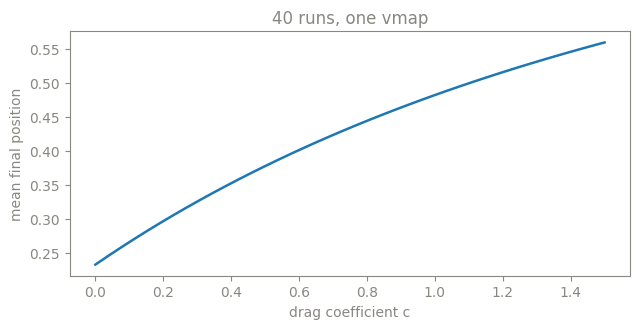

In [6]:
import matplotlib.pyplot as plt

drags = np.linspace(0.0, 1.5, 40)
final_x = jax.jit(jax.vmap(lambda c: run(c)[0].mean()))(drags)

fig, ax = plt.subplots(figsize=(6.5, 3.4))
ax.plot(drags, final_x, lw=1.8)
ax.set(xlabel="drag coefficient c", ylabel="mean final position", title="40 runs, one vmap")
plt.tight_layout()

## A gradient with no `where`

For gradients, swap `while_loop` for `lax.scan` with a fixed length: JAX differentiates scans, and eagle's rule for a
carried-state kernel treats a stopped oscillator as passing its gradient straight through. The check is the same loop
written in `jax.numpy` with the `where` spelled out.

In [7]:
LENGTH = 200      # 200 steps of 0.01 reach the longest final time, 2.0


def mean_x(c):
    final = lax.scan(lambda s, _: (advance(c, s), None), start, None, length=LENGTH)[0]
    return final[0].sum()


def mean_x_reference(c):
    def body(s, _):
        x, v, t, done = s
        vn, xn, tn = v - DT * (x + c * v), x + DT * v, t + DT
        return (jnp.where(done, x, xn), jnp.where(done, v, vn), jnp.where(done, t, tn), done | (tn >= t_final)), None
    return lax.scan(body, start, None, length=LENGTH)[0][0].sum()


g, g_ref = jax.jit(jax.grad(mean_x))(0.3), jax.jit(jax.grad(mean_x_reference))(0.3)
rel = abs(float(g) - float(g_ref)) / abs(float(g_ref))
print(f"d(sum x)/dc = {float(g):.6f}; plain JAX {float(g_ref):.6f}; relative difference {rel:.1e}")
assert rel < 1e-12

d(sum x)/dc = 142.827573; plain JAX 142.827573; relative difference 2.0e-16


## What stays outside `jit`

Inside `jit` the loop belongs to XLA, so `until_done`'s own tools (compaction of finished samples, conditionals, event
refinement, windowed reverse) are not there; they are the reason to stay with `until_done` and put a JAX model in it
as in [tutorial 17](17_a_jax_model_between_eagle_launches). JAX's loops also set what is differentiable. Here is what
you get if you try, the first line of each message:

In [8]:
def first_line(call):
    try:
        call()
    except Exception as err:
        return f"{type(err).__name__}: {str(err).splitlines()[0][:120]}"
    return "worked"


print("grad through while_loop:", first_line(lambda: jax.grad(lambda c: run(c)[0].sum())(0.3)))
print("forward mode:           ", first_line(lambda: jax.jacfwd(mean_x)(0.3)))
print("reverse Jacobian:       ", first_line(lambda: jax.jacrev(mean_x)(0.3)))

grad through while_loop: ValueError: Reverse-mode differentiation does not work for lax.while_loop or lax.fori_loop with dynamic start/stop values. Try using


forward mode:            TypeError: can't apply forward-mode autodiff (jvp) to a custom_vjp function.


reverse Jacobian:        worked


## Limits

- <!-- limit: jax-inside-jit --> Compaction, conditionals and event refinement belong to `until_done`; inside `jit` the loop is XLA's (`while_loop`, `scan`), so they do not apply there (XLA's design): use `until_done` when you need them.
- <!-- limit: jax-while-grad --> `jax.grad` does not go through `lax.while_loop`, because the trip count is only known at run time (JAX's rule): use `lax.scan` with a fixed length for gradients, as this page does.
- <!-- limit: jax-state-forward --> Forward mode (`jvp`, `jacfwd`) of a kernel that carries state is not available yet (our scope): use reverse mode (`grad`, `jacrev`), or a kernel that writes a separate output plane.

## Which one when

Mostly eagle with a JAX model in the loop: [tutorial 17](17_a_jax_model_between_eagle_launches), where eagle keeps
compaction, events and reverse. Mostly JAX with eagle kernels as ops: this page, with `while_loop` to run and `scan`
to differentiate. [eagle inside your JAX program](../../interop/jax) has the full picture.